# Regularization in Machine Learning
This notebook covers the fundamental concepts of **Overfitting** and **Regularization** in regression and classification models.

---
## Table of Contents
1. [Introduction to Overfitting and Regularization](#1.-Introduction-to-Overfitting-and-Regularization)
2. [Regression with Regularization (Cosine Dataset)](#2.-Regression-with-Regularization)
   - [2.1 Synthetic Data Generation](#2.1-Synthetic-Data-Generation)
   - [2.2 Polynomial Regression without Regularization](#2.2-Polynomial-Regression)
   - [2.3 L2 Regularization (Ridge Regression)](#2.3-L2-Regularization-(Ridge))
   - [2.4 L1 Regularization (Lasso Regression)](#2.4-L1-Regularization-(Lasso))
3. [Direct Comparison of Ridge and Lasso (from 01-Linear_Regression)](#3.-Direct-Comparison-of-Ridge-and-Lasso-Regression)
   - [3.1 Polynomial Fitting across Degrees and Lambdas](#3.1-Polynomial-Fitting-across-Degrees-and-Lambdas)
   - [3.2 RMSE vs Regularization Parameter Analysis](#3.2-RMSE-vs-Regularization-Parameter)
4. [Classification with Regularization (Logistic Regression)](#4.-Classification-with-Regularization)


## 1. Introduction to Overfitting and Regularization

### Overfitting:
- A very common problem in machine learning.
- Occurs when the model is **much more complex** than it should be (e.g., using a high polynomial degree or too many features).
  - It performs exceptionally well on the training data.
  - It performs poorly on new, unseen data (high variance).
- In such situations, the model **fails to generalize**.

### Regularization:
- An effective technique to avoid or reduce overfitting.
- **Core Idea:** Keep the magnitude of the parameters as small as possible by introducing a **penalty for large weight values**.
- Regularization transforms training into a **multi-objective optimization** problem:
  1. Fit the training data as accurately as possible (minimize empirical error).
  2. Keep the model parameters small and simple (minimize model complexity).

This is achieved by adding a regularization term to our cost function:

$$J(\theta) = \text{Cost}(X, y, \theta) + \lambda R(\theta)$$

- The second term $R(\theta)$ is the **regularization term** (penalty).
- The hyperparameter $\lambda \ge 0$ (or $\alpha$) is the **regularization strength**, controlling the tradeoff between fitting the data and parameter shrinkage.


In [50]:
import numpy as np
import matplotlib.pyplot as plt
import warnings

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.datasets import make_moons

# Initial plotting setup
plt.rcParams['figure.figsize'] = [12, 6]
plt.rcParams['figure.dpi'] = 140
plt.style.use('ggplot')

np.random.seed(0)
np.set_printoptions(precision=2, linewidth=100)
warnings.filterwarnings(action='ignore')


## 2. Regression with Regularization

### 2.1 Synthetic Data Generation
We generate synthetic data using a nonlinear ground-truth function $f(x) = \cos(1.5\pi x)$ corrupted by Gaussian noise.


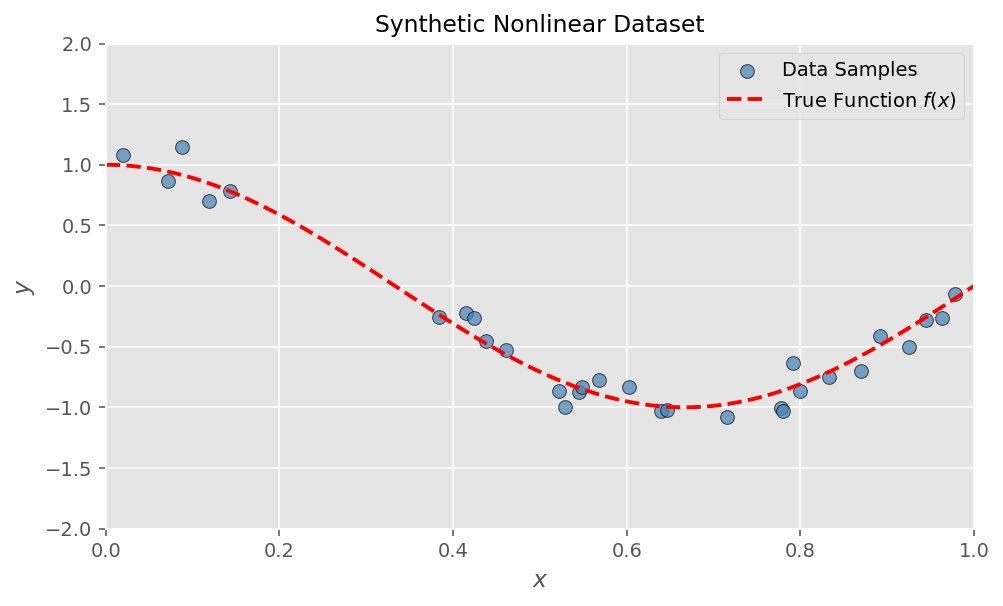

In [36]:
def f(x):
    return np.cos(1.5 * np.pi * x)

def generate_data(n_samples=30):
    x = np.sort(np.random.rand(n_samples))
    y = f(x) + 0.1 * np.random.randn(n_samples)
    return x, y

n_samples = 30
x, y = generate_data(n_samples)

plt.figure(figsize=(8, 4.5))
plt.scatter(x, y, s=50, edgecolors='k', alpha=0.7, color='steelblue', label='Data Samples')
x_plot = np.linspace(0, 1, 100)
plt.plot(x_plot, f(x_plot), 'r--', label='True Function $f(x)$', lw=2)
plt.xlim(0, 1)
plt.ylim(-2, 2)
plt.title('Synthetic Nonlinear Dataset', fontsize=12)
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend()
plt.show()


### 2.2 Polynomial Regression
First, we fit unregularized polynomial models of varying degrees $d \in [1, 3, 5, 7, 9, 11, 13, 15]$. Notice how higher degrees begin oscillating wildly to interpolate noisy points.


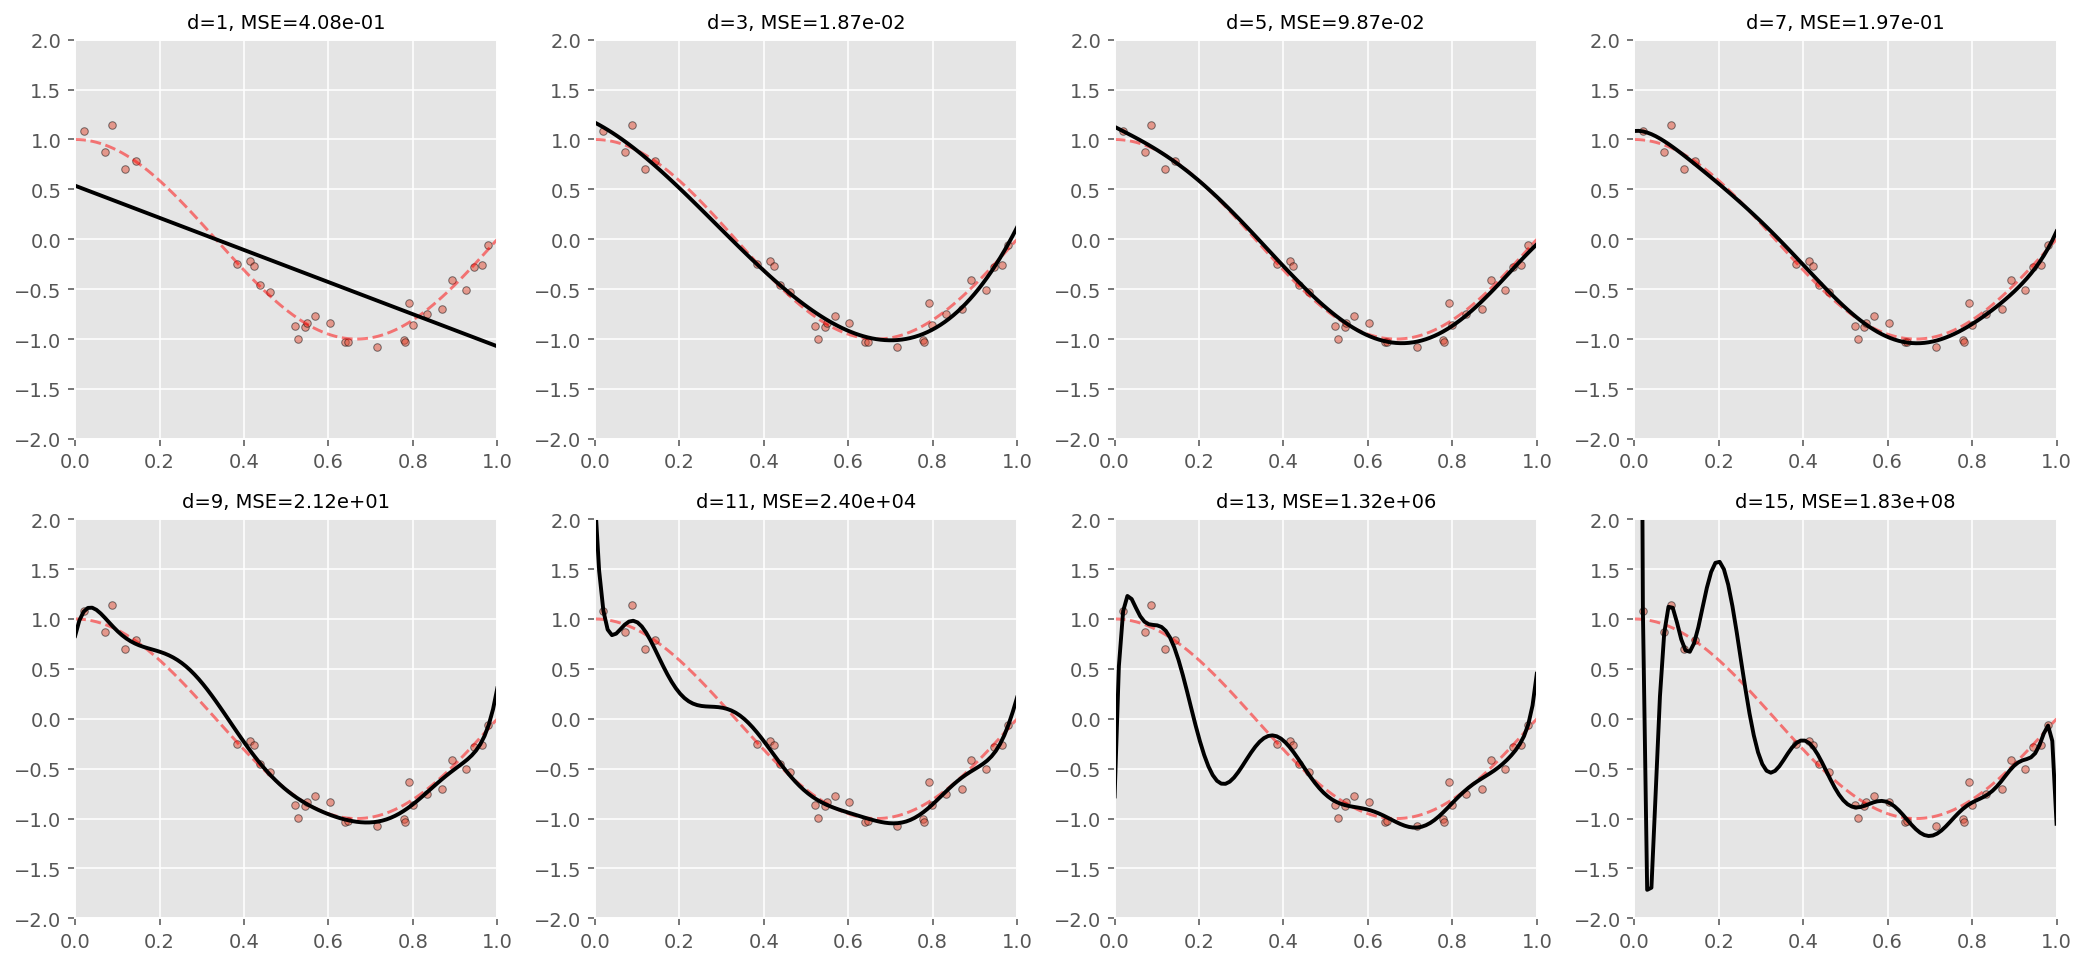

In [37]:
def fit_poly(x, y, degree=1):
    polynomial_features = PolynomialFeatures(degree=degree, include_bias=False)
    linear_regression = LinearRegression()
    model = Pipeline([("polynomial_features", polynomial_features), ("linear_regression", linear_regression)])
    model.fit(x[:, None], y)
    return model

degrees = [1, 3, 5, 7, 9, 11, 13, 15]

plt.figure(figsize=(15, 7))

for d in degrees:
    model = fit_poly(x, y, degree=d)
    scores = cross_val_score(model, x[:, None], y, scoring="neg_mean_squared_error", cv=10)

    plt.subplot(2, 4, degrees.index(d) + 1)
    plt.tight_layout()

    x_test = np.linspace(0, 1, 100)
    plt.plot(x_test, f(x_test), 'r--', label="Target", alpha=0.5)
    plt.scatter(x, y, s=15, edgecolor='k', alpha=0.5, label="Samples")
    plt.plot(x_test, model.predict(x_test[:, None]), 'k', lw=2, label="Predicted")
    plt.xlim((0, 1))
    plt.ylim((-2, 2))
    plt.title("d={}, MSE={:.2e}".format(d, -scores.mean()), fontsize=10)

plt.show()


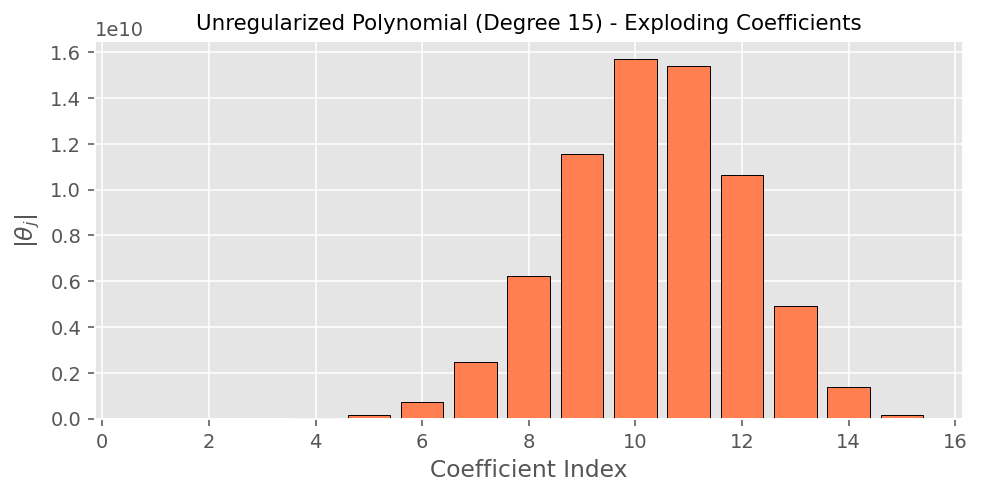

In [38]:
def plot_coef(theta, title='Model Coefficients'):
    plt.figure(figsize=(8, 3.5))
    plt.bar(np.arange(1, len(theta) + 1), height=np.abs(theta), color='coral', edgecolor='k')
    plt.xlabel('Coefficient Index')
    plt.ylabel(r'$|\theta_j|$')
    plt.title(title, fontsize=11)
    plt.show()

# Coefficients of the unregularized degree 15 model:
plot_coef(model.steps[1][1].coef_, title='Unregularized Polynomial (Degree 15) - Exploding Coefficients')


### 2.3 L2-Regularization (Ridge)

$$J(\theta) = \frac{1}{2m} \sum_{i=1}^{m} (h_\theta(x^{(i)}) - y^{(i)})^2 + \frac{\lambda}{2m} \sum_{j=1}^{n} \theta_j^2$$

The $L_2$ penalty adds the sum of squared weights. This penalizes large weights and forces coefficients to shrink smoothly towards zero (**weight shrinkage**).


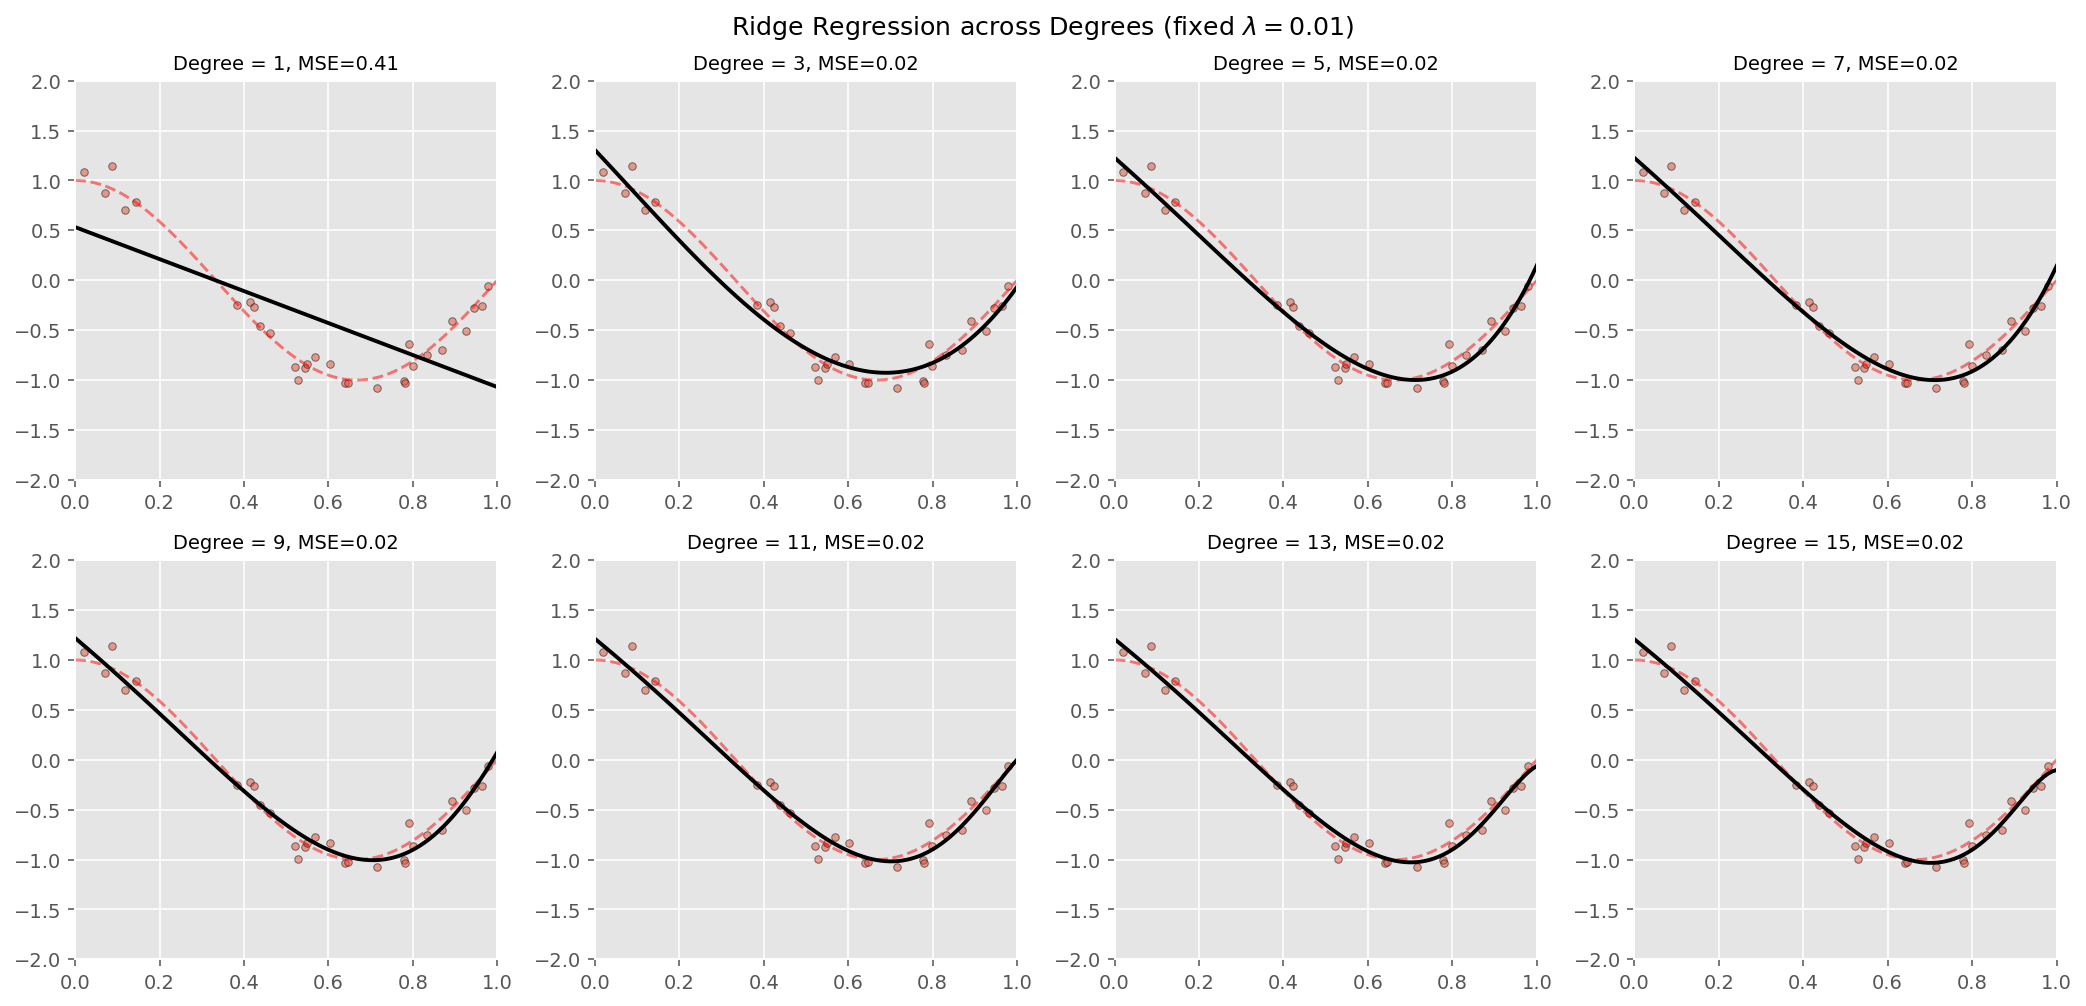

In [39]:
def fit_poly_L2_reg(degree=1, lmbda=1.0):
    polynomial_features = PolynomialFeatures(degree=degree, include_bias=False)
    linear_regression = Ridge(alpha=lmbda)
    model = Pipeline([("polynomial_features", polynomial_features), ("linear_regression", linear_regression)])
    model.fit(x[:, None], y)
    return model

lmbda = 1e-2

plt.figure(figsize=(15, 7))

for d in degrees:
    model = fit_poly_L2_reg(degree=d, lmbda=lmbda)
    scores = cross_val_score(model, x[:, None], y, scoring="neg_mean_squared_error", cv=10)

    plt.subplot(2, 4, degrees.index(d) + 1)
    plt.tight_layout()

    x_test = np.linspace(0, 1, 100)
    plt.plot(x_test, f(x_test), 'r--', label="Target", alpha=0.5)
    plt.scatter(x, y, s=15, edgecolor='k', alpha=0.5, label="Samples")
    plt.plot(x_test, model.predict(x_test[:, None]), 'k', lw=2, label="Predicted")
    plt.xlim((0, 1))
    plt.ylim((-2, 2))
    plt.title("Degree = {}, MSE={:.2f}".format(d, -scores.mean()), fontsize=10)

plt.suptitle(f'Ridge Regression across Degrees (fixed $\\lambda = {lmbda}$)', fontsize=13, y=1.02)
plt.show()


#### Visualizing the effect of $\lambda$ on Ridge Regression:
Now we fix the polynomial degree to $d = 15$ and vary the regularization parameter $\lambda$ from $10^{-10}$ to $100$.


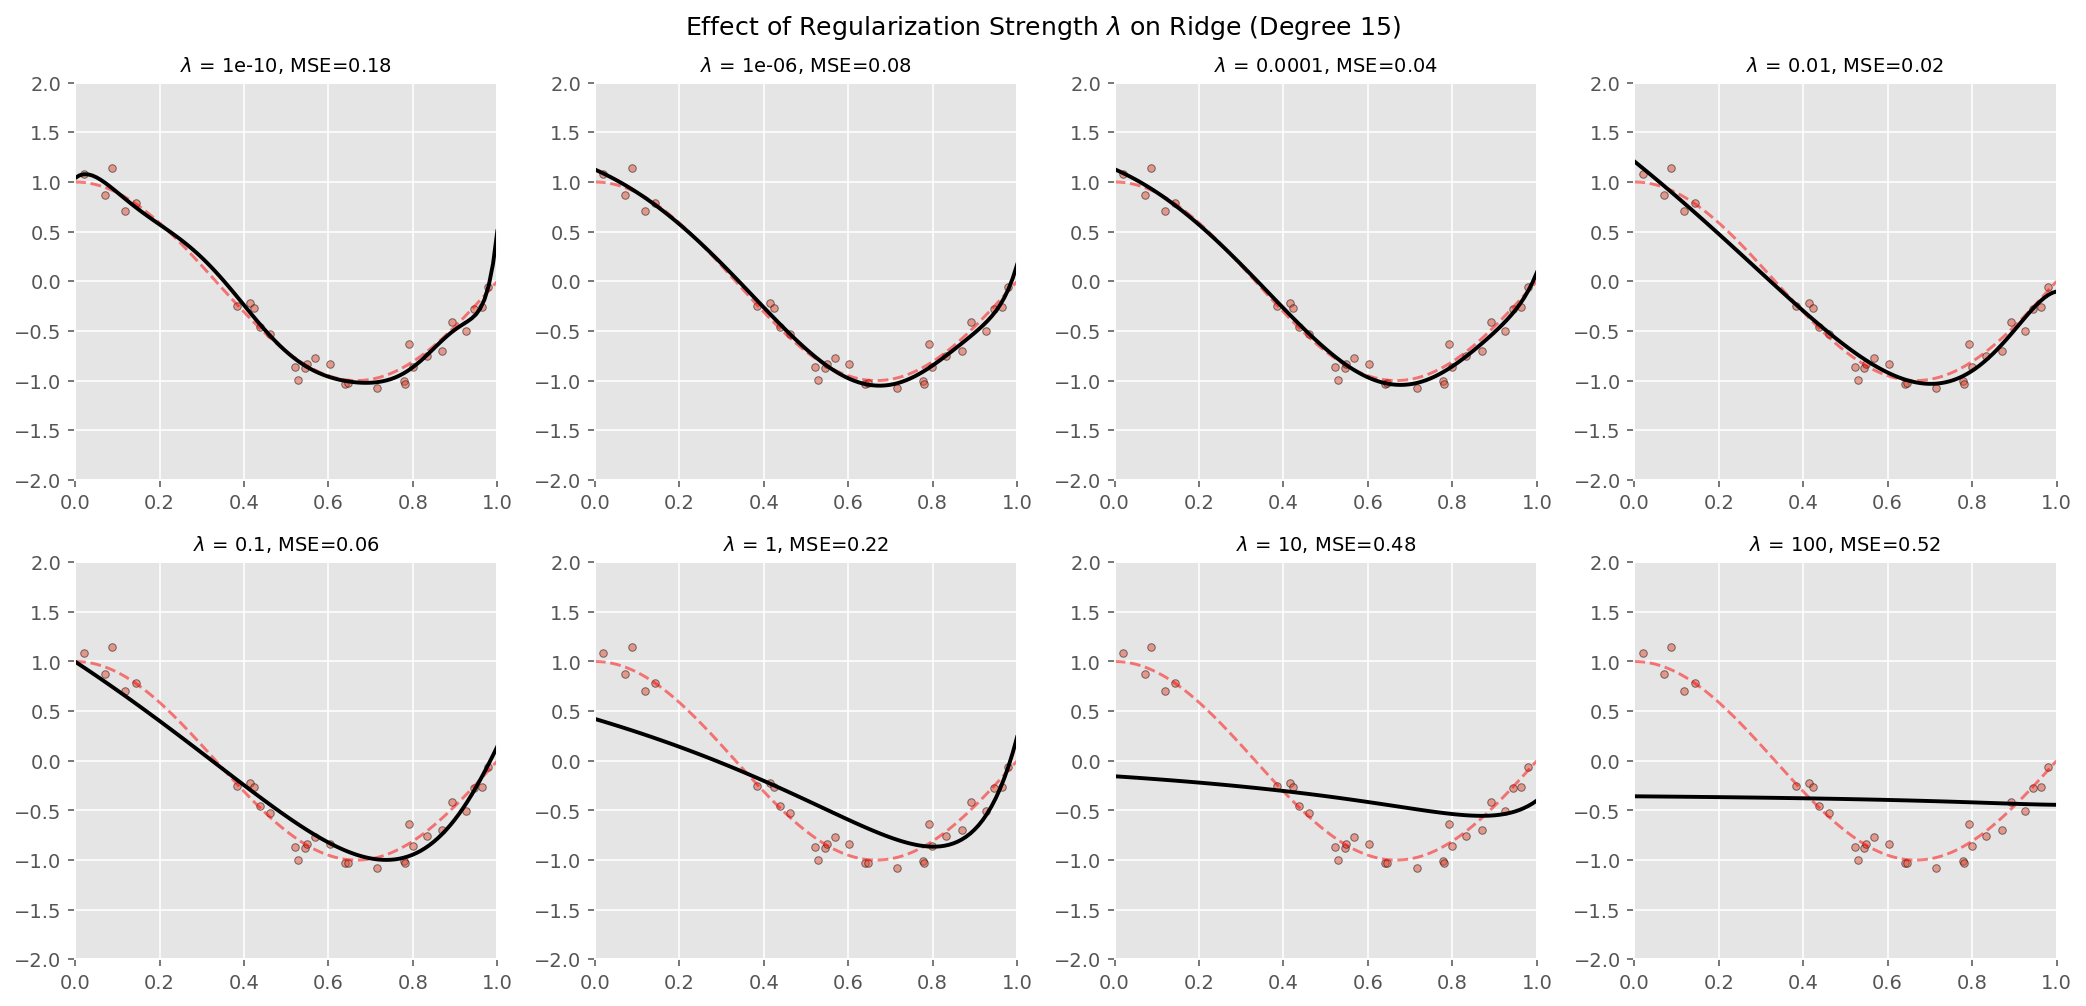

In [40]:
lmbdas = [1e-10, 1e-6, 1e-4, 1e-2, 1e-1, 1, 10, 100]

plt.figure(figsize=(15, 7))

for lmbda_val in lmbdas:
    model = fit_poly_L2_reg(degree=15, lmbda=lmbda_val)
    scores = cross_val_score(model, x[:, None], y, scoring="neg_mean_squared_error", cv=10)

    plt.subplot(2, 4, lmbdas.index(lmbda_val) + 1)
    plt.tight_layout()
    x_test = np.linspace(0, 1, 100)
    plt.plot(x_test, f(x_test), 'r--', label="Target", alpha=0.5)
    plt.scatter(x, y, s=15, edgecolor='k', alpha=0.5, label="Samples")
    plt.plot(x_test, model.predict(x_test[:, None]), 'k', lw=2, label="Predicted")
    plt.xlim((0, 1))
    plt.ylim((-2, 2))
    plt.title(rf"$\lambda$ = {lmbda_val}, MSE={-scores.mean():.2f}", fontsize=10)

plt.suptitle('Effect of Regularization Strength $\\lambda$ on Ridge (Degree 15)', fontsize=13, y=1.02)
plt.show()


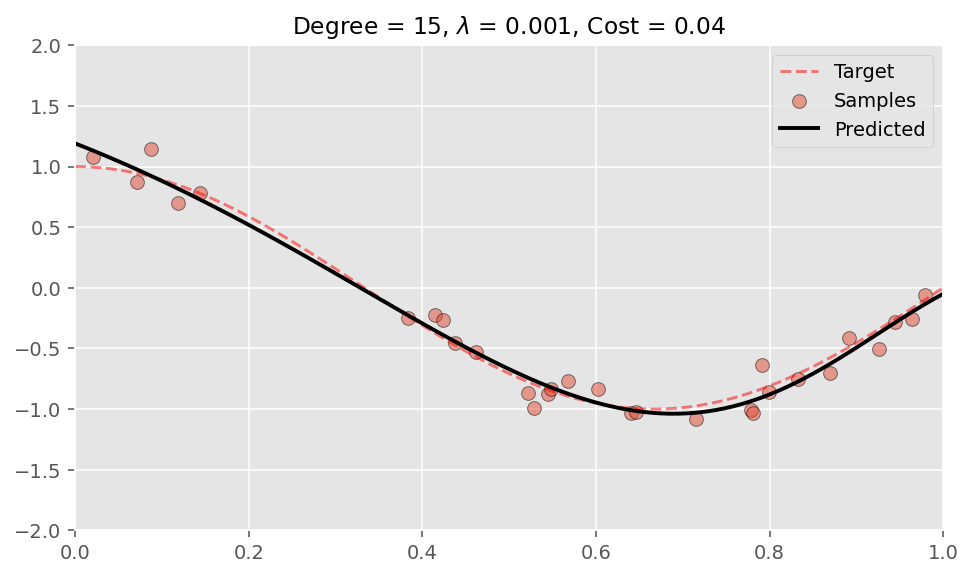

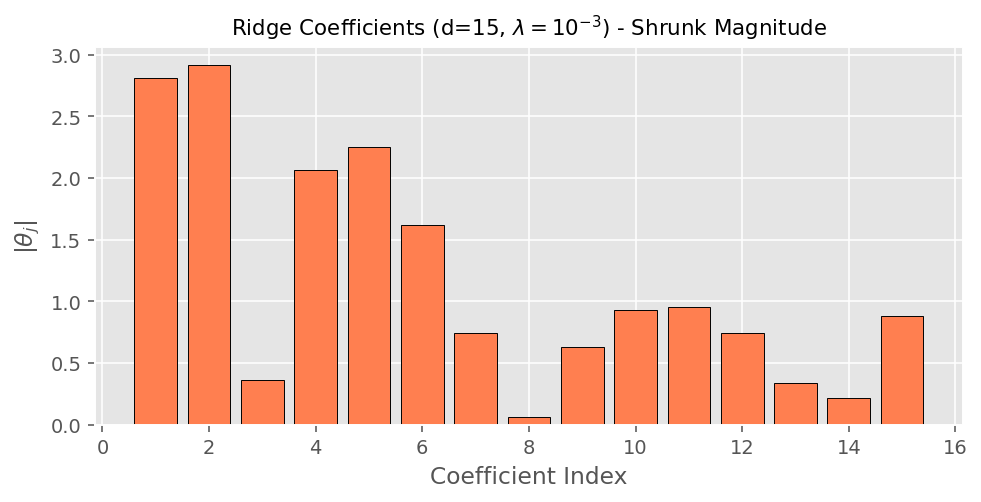

In [41]:
# Detailed fit for degree 15 with optimal lambda = 1e-3
degree = 15
lmbda = 1e-3

model = fit_poly_L2_reg(degree, lmbda)
scores = cross_val_score(model, x[:, None], y, scoring="neg_mean_squared_error", cv=10)

fig, ax = plt.subplots(figsize=(8, 4.5))
x_test = np.linspace(0, 1, 100)
ax.plot(x_test, f(x_test), 'r--', label="Target", alpha=0.5)
ax.scatter(x, y, s=50, edgecolor='k', alpha=0.5, label="Samples")
ax.plot(x_test, model.predict(x_test[:, None]), 'k', lw=2, label="Predicted")
ax.set_xlim((0, 1))
ax.set_ylim((-2, 2))
ax.set_title(rf"Degree = {degree}, $\lambda$ = {lmbda}, Cost = {-scores.mean():.2f}", fontsize=12)
ax.legend()
plt.show()

plot_coef(model.steps[1][1].coef_, title=r'Ridge Coefficients (d=15, $\lambda=10^{-3}$) - Shrunk Magnitude')


### 2.4 L1-Regularization (Lasso)

$$J(\theta) = \frac{1}{2m} \sum_{i=1}^{m} (h_\theta(x^{(i)}) - y^{(i)})^2 + \frac{\lambda}{m} \sum_{j=1}^{n} |\theta_j|$$

The $L_1$ penalty adds the sum of absolute values of the weights. This drives irrelevant weights to **exactly zero**, producing a **sparse model** and performing embedded feature selection.


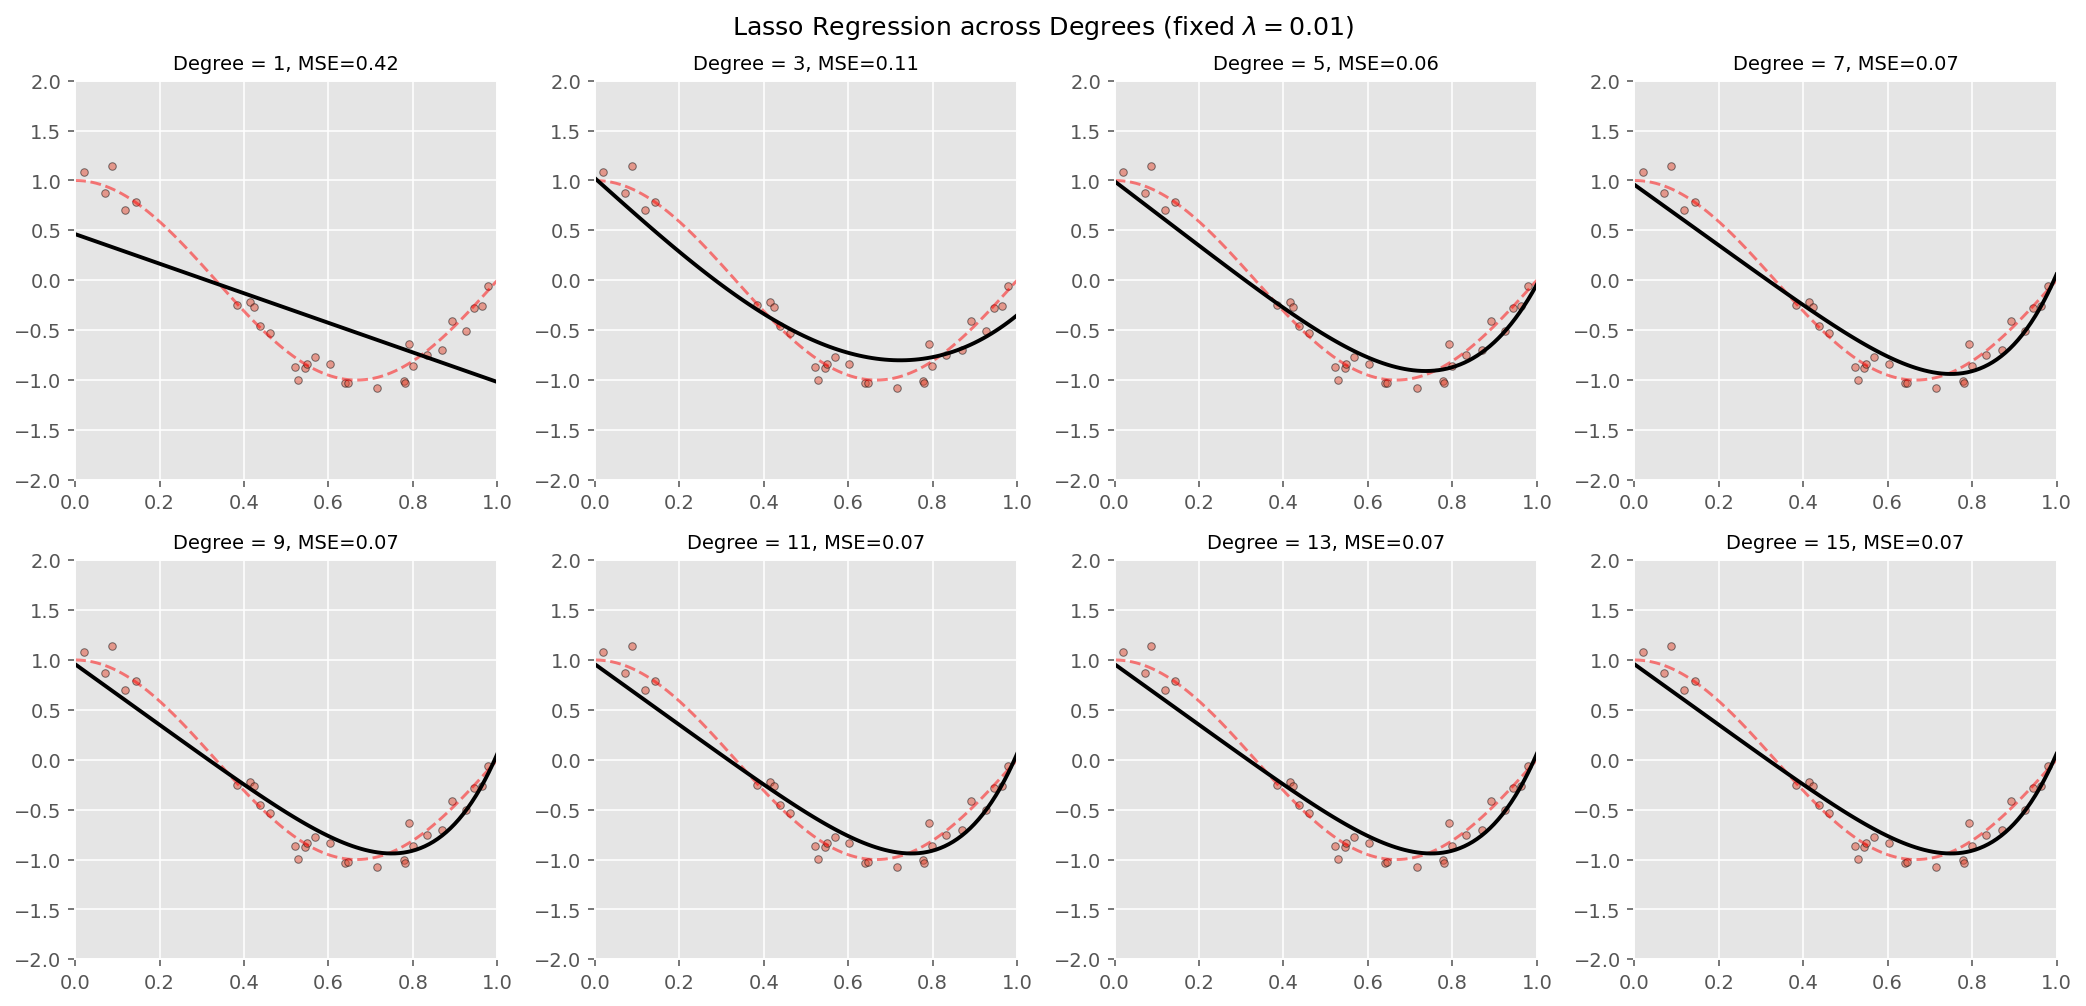

In [42]:
def fit_poly_L1_reg(degree=1, lmbda=1.0):
    polynomial_features = PolynomialFeatures(degree=degree, include_bias=False)
    l1_regression = Lasso(alpha=lmbda, max_iter=10000)
    model = Pipeline([("poly", polynomial_features), ("l1_reg", l1_regression)])
    model.fit(x[:, None], y)
    return model

lmbda = 1e-2

plt.figure(figsize=(15, 7))

for d in degrees:
    model = fit_poly_L1_reg(degree=d, lmbda=lmbda)
    scores = cross_val_score(model, x[:, None], y, scoring="neg_mean_squared_error", cv=10)

    plt.subplot(2, 4, degrees.index(d) + 1)
    plt.tight_layout()
    x_test = np.linspace(0, 1, 100)
    plt.plot(x_test, f(x_test), 'r--', label="Target", alpha=0.5)
    plt.scatter(x, y, s=15, edgecolor='k', alpha=0.5, label="Samples")
    plt.plot(x_test, model.predict(x_test[:, None]), 'k', lw=2, label="Predicted")
    plt.xlim((0, 1))
    plt.ylim((-2, 2))
    plt.title(f"Degree = {d}, MSE={-scores.mean():.2f}", fontsize=10)

plt.suptitle(f'Lasso Regression across Degrees (fixed $\\lambda = {lmbda}$)', fontsize=13, y=1.02)
plt.show()


#### Visualizing the effect of $\lambda$ on Lasso Regression:


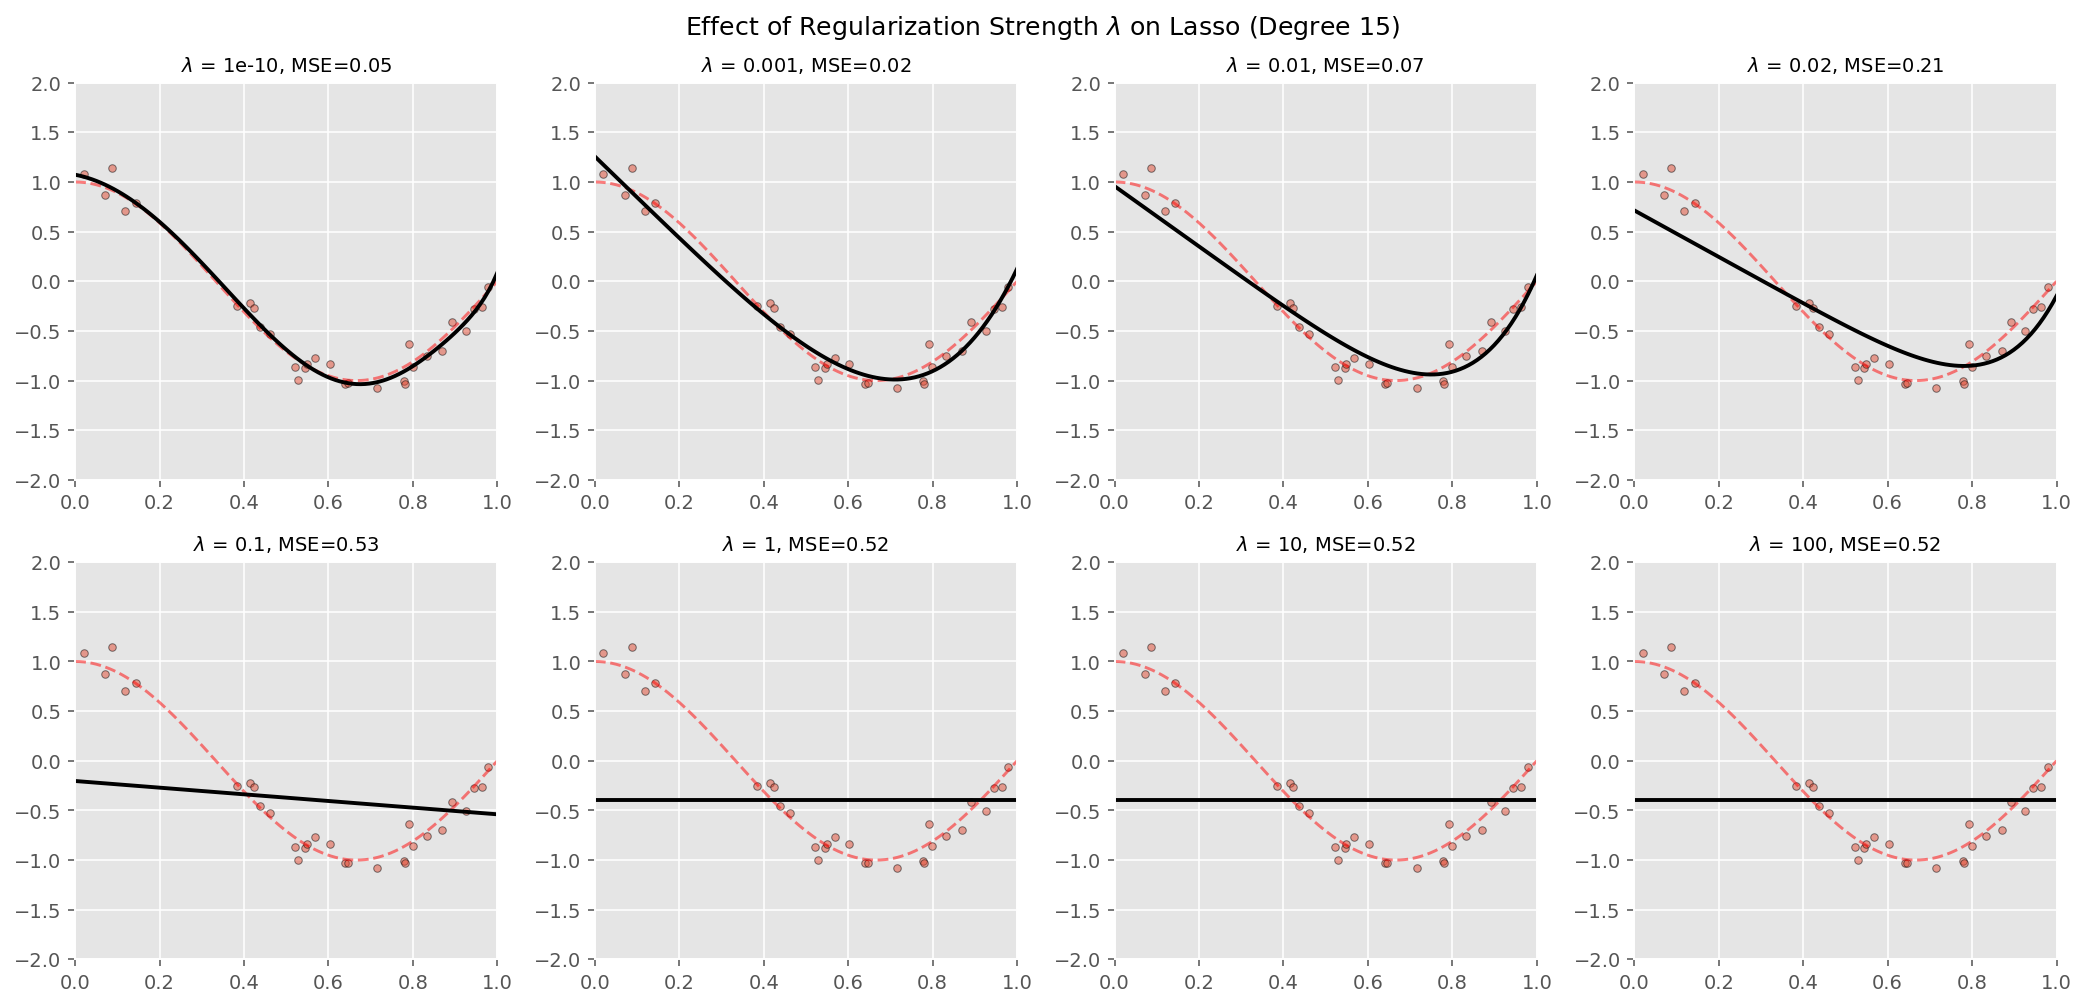

In [43]:
lmbdas = [1e-10, 1e-3, 1e-2, 2e-2, 1e-1, 1, 10, 100]

plt.figure(figsize=(15, 7))

for lmbda_val in lmbdas:
    model = fit_poly_L1_reg(degree=15, lmbda=lmbda_val)
    scores = cross_val_score(model, x[:, None], y, scoring="neg_mean_squared_error", cv=10)

    plt.subplot(2, 4, lmbdas.index(lmbda_val) + 1)
    plt.tight_layout()
    x_test = np.linspace(0, 1, 100)
    plt.plot(x_test, f(x_test), 'r--', label="Target", alpha=0.5)
    plt.scatter(x, y, s=15, edgecolor='k', alpha=0.5, label="Samples")
    plt.plot(x_test, model.predict(x_test[:, None]), 'k', lw=2, label="Predicted")
    plt.xlim((0, 1))
    plt.ylim((-2, 2))
    plt.title(rf"$\lambda$ = {lmbda_val}, MSE={-scores.mean():.2f}", fontsize=10)

plt.suptitle('Effect of Regularization Strength $\\lambda$ on Lasso (Degree 15)', fontsize=13, y=1.02)
plt.show()


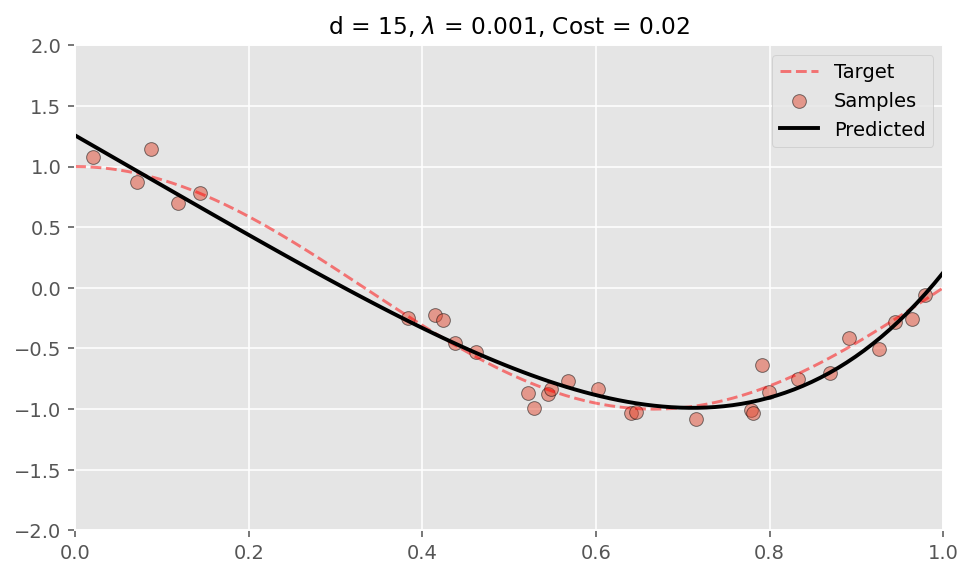

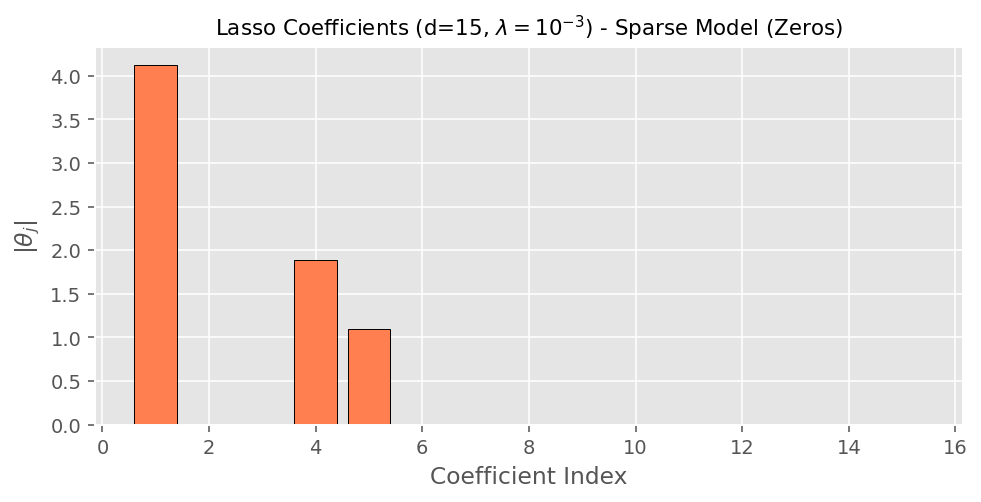

Number of coefficients driven to exactly zero: 12 out of 15


In [44]:
# Detailed fit for degree 15 with lambda = 1e-3
degree = 15
lmbda = 1e-3

model = fit_poly_L1_reg(degree=degree, lmbda=lmbda)
scores = cross_val_score(model, x[:, None], y, scoring="neg_mean_squared_error", cv=10)

fig, ax = plt.subplots(figsize=(8, 4.5))
x_test = np.linspace(0, 1, 100)
ax.plot(x_test, f(x_test), 'r--', label="Target", alpha=0.5)
ax.scatter(x, y, s=50, edgecolor='k', alpha=0.5, label="Samples")
ax.plot(x_test, model.predict(x_test[:, None]), 'k', lw=2, label="Predicted")
ax.set_xlim((0, 1))
ax.set_ylim((-2, 2))
ax.set_title(rf"d = {degree}, $\lambda$ = {lmbda}, Cost = {-scores.mean():.2f}", fontsize=12)
ax.legend()
plt.show()

# Notice the sparsity (many coefficients are exactly zero):
plot_coef(model.steps[1][1].coef_, title=r'Lasso Coefficients (d=15, $\lambda=10^{-3}$) - Sparse Model (Zeros)')
num_zeros = np.sum(model.steps[1][1].coef_ == 0)
print(f"Number of coefficients driven to exactly zero: {num_zeros} out of {degree}")


## 3. Direct Comparison of Ridge and Lasso Regression

In this section, we directly compare the effect of regularization using **L1 norm (Lasso regression)** and **L2 norm (Ridge regression)** on the same dataset across multiple polynomial degrees and $\lambda$ values.

Let us generate a small number of data points from a quadratic function $y = X^2 - 2X + \text{noise}$ and fit complex models to it:


In [51]:
# Define Root Mean Square Error helper function
def compute_rms_error(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def generate_comparison_data(n=100, noise=10.0):
    np.random.seed(42)
    X = np.random.uniform(-10, 10, n)
    y = X**2 - 2 * X + np.random.randn(n) * noise
    return X, y

X_comp, y_comp = generate_comparison_data(n=15)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_comp, y_comp, test_size=0.2, random_state=42)

print(f"Dataset generated: {len(X_train_c)} training samples, {len(X_test_c)} test samples.")


Dataset generated: 12 training samples, 3 test samples.


### 3.1 Polynomial Fitting across Degrees and Lambdas
We now fit Ridge and Lasso models across degrees `[2, 6, 8]` and regularization parameters $\lambda \in [10^4, 1, 10^{-4}, 10^{-8}]$, plotting the fitted curves side-by-side.


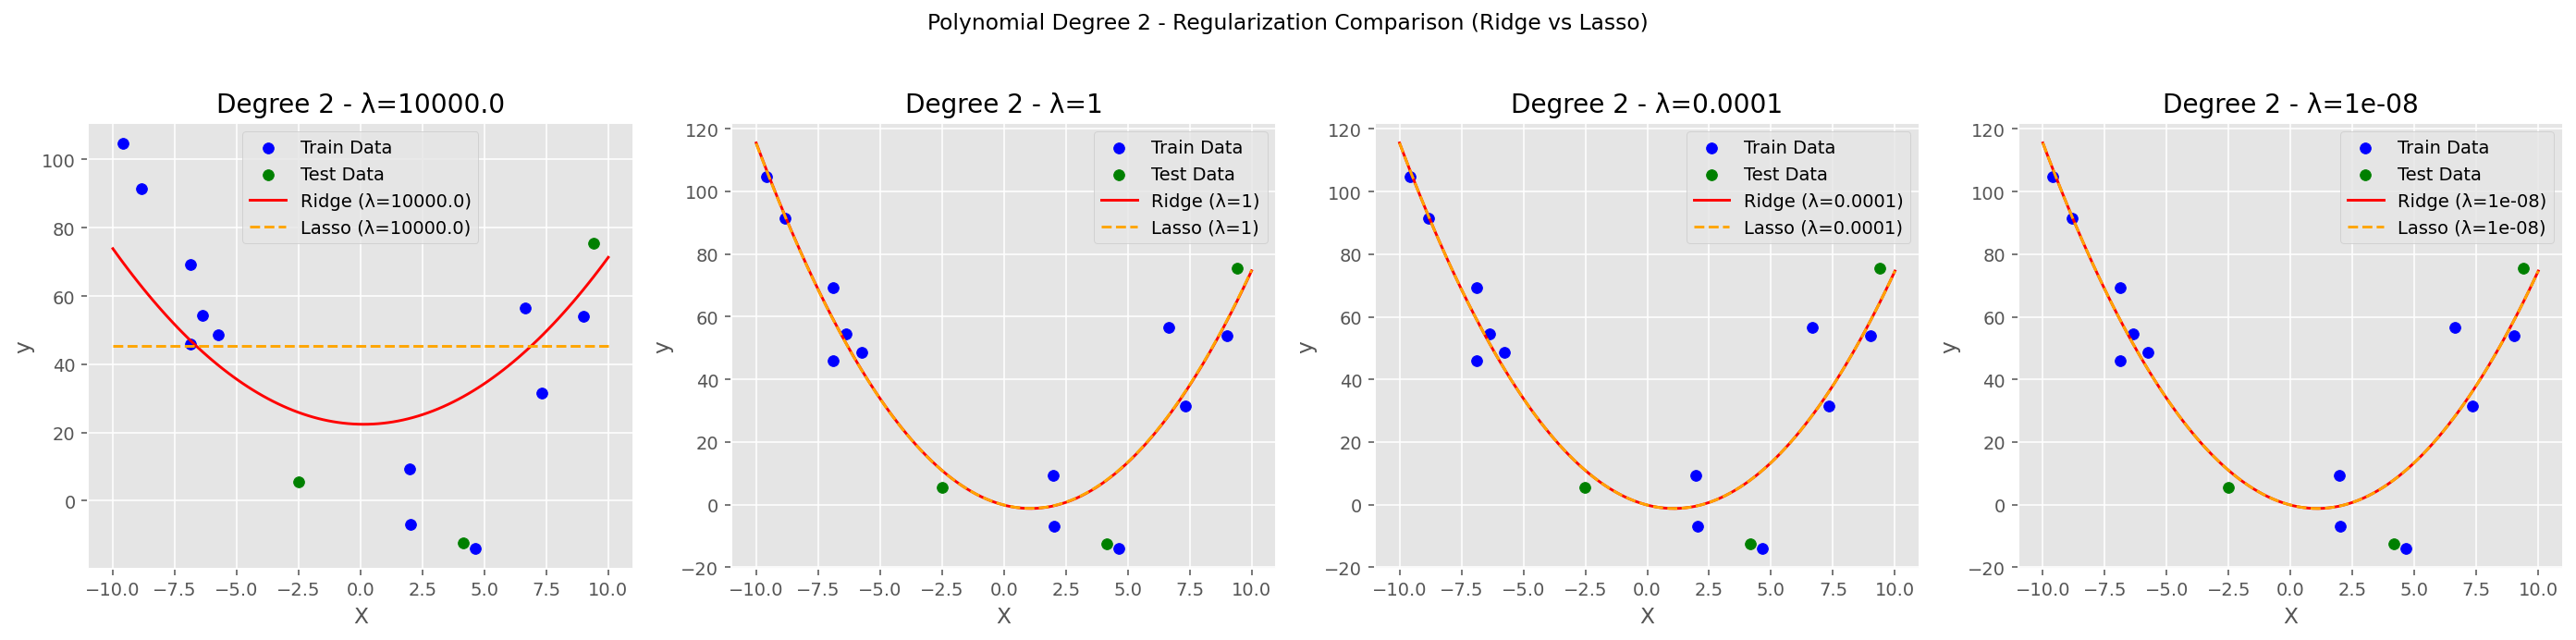

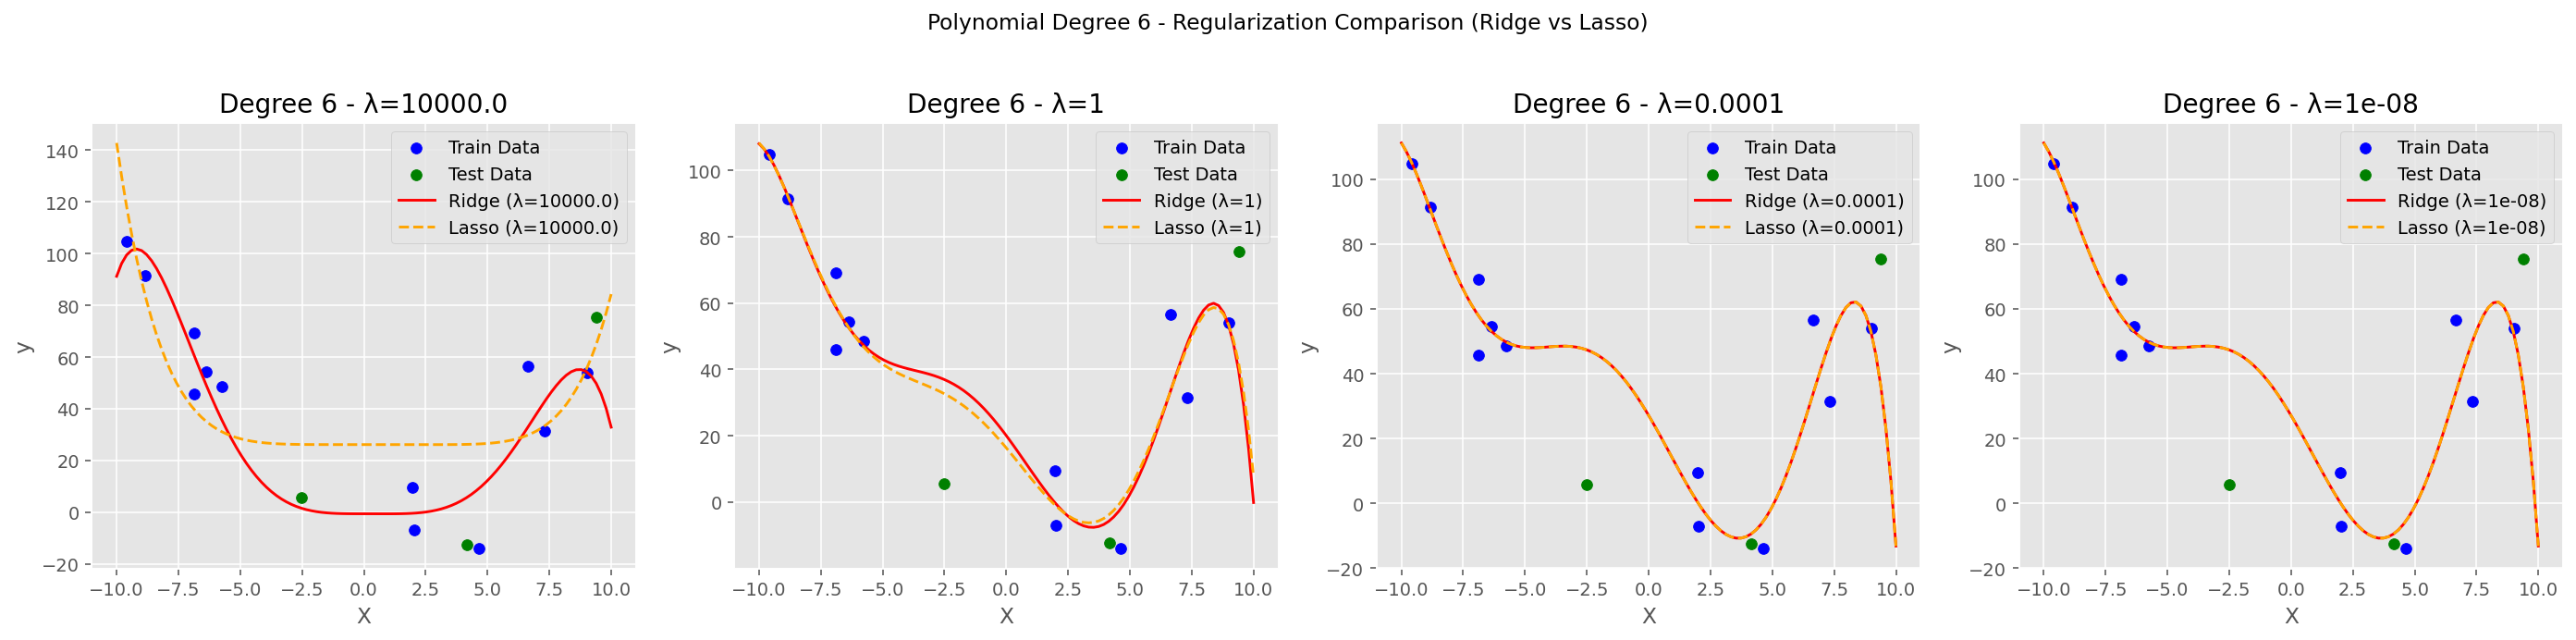

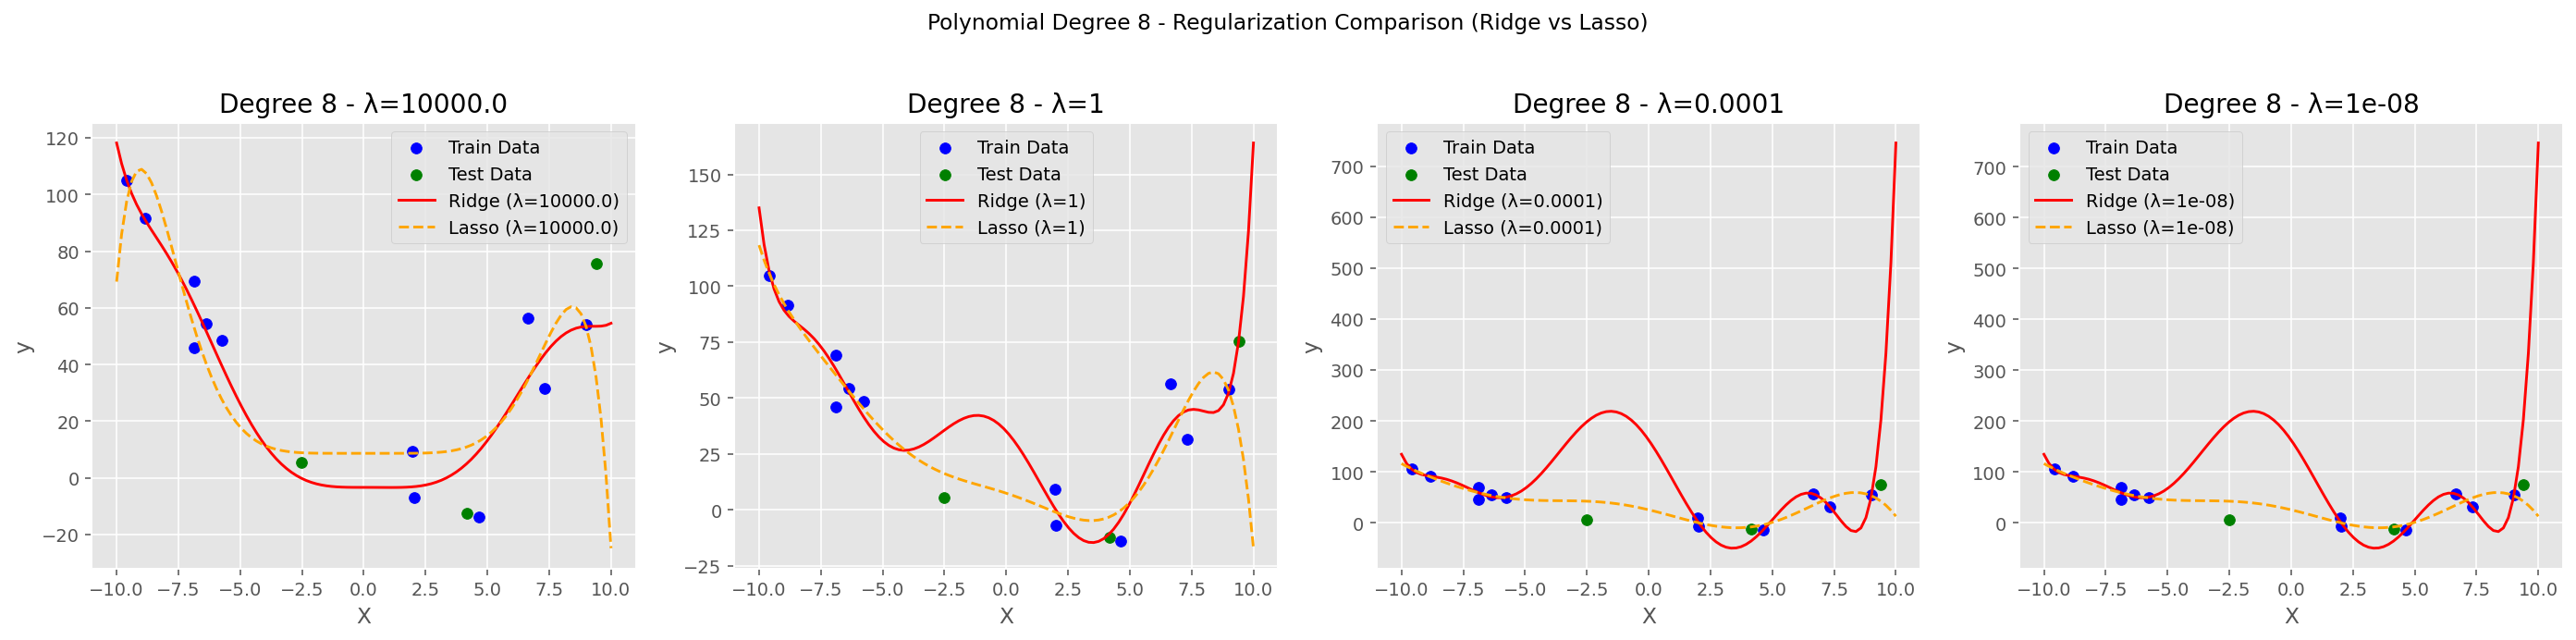

In [46]:
degrees = [2, 6, 8]
lambdas = [1e4, 1, 1e-4, 1e-8]

ridge_rmse_train = np.zeros((len(degrees), len(lambdas)))
ridge_rmse_test = np.zeros((len(degrees), len(lambdas)))
lasso_rmse_train = np.zeros((len(degrees), len(lambdas)))
lasso_rmse_test = np.zeros((len(degrees), len(lambdas)))

for degree_idx, degree in enumerate(degrees):
    fig, axs = plt.subplots(1, 4, figsize=(20, 5))
    for lambda_idx, lambda_val in enumerate(lambdas):
        poly_features = PolynomialFeatures(degree=degree)
        X_train_poly = poly_features.fit_transform(X_train_c[:, np.newaxis])
        X_test_poly = poly_features.transform(X_test_c[:, np.newaxis])

        # Ridge Regression using scikit-learn
        ridge_model = Ridge(alpha=lambda_val)
        ridge_model.fit(X_train_poly, y_train_c)
        y_train_pred_ridge = ridge_model.predict(X_train_poly)
        y_test_pred_ridge = ridge_model.predict(X_test_poly)

        # Lasso Regression using scikit-learn
        lasso_model = Lasso(alpha=lambda_val, max_iter=10000)
        lasso_model.fit(X_train_poly, y_train_c)
        y_train_pred_lasso = lasso_model.predict(X_train_poly)
        y_test_pred_lasso = lasso_model.predict(X_test_poly)

        ridge_rmse_train[degree_idx, lambda_idx] = compute_rms_error(y_train_c, y_train_pred_ridge)
        ridge_rmse_test[degree_idx, lambda_idx] = compute_rms_error(y_test_c, y_test_pred_ridge)
        lasso_rmse_train[degree_idx, lambda_idx] = compute_rms_error(y_train_c, y_train_pred_lasso)
        lasso_rmse_test[degree_idx, lambda_idx] = compute_rms_error(y_test_c, y_test_pred_lasso)

        # Plot fitted curves for both Ridge and Lasso
        X_plot = np.linspace(-10, 10, 100)
        X_plot_poly = poly_features.transform(X_plot[:, np.newaxis])

        y_plot_ridge = ridge_model.predict(X_plot_poly)
        y_plot_lasso = lasso_model.predict(X_plot_poly)

        ax = axs[lambda_idx]
        ax.scatter(X_train_c, y_train_c, color='blue', label='Train Data')
        ax.scatter(X_test_c, y_test_c, color='green', label='Test Data')
        ax.plot(X_plot, y_plot_ridge, color='red', label=f'Ridge (λ={lambda_val})')
        ax.plot(X_plot, y_plot_lasso, color='orange', linestyle='--', label=f'Lasso (λ={lambda_val})')
        ax.set_title(f'Degree {degree} - λ={lambda_val}')
        ax.set_xlabel('X')
        ax.set_ylabel('y')
        ax.legend()

    plt.suptitle(f'Polynomial Degree {degree} - Regularization Comparison (Ridge vs Lasso)')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


### 3.2 RMSE vs Regularization Parameter
We plot the Test RMSE as a function of $\lambda$ (on a logarithmic scale) for both Ridge and Lasso across different polynomial degrees.


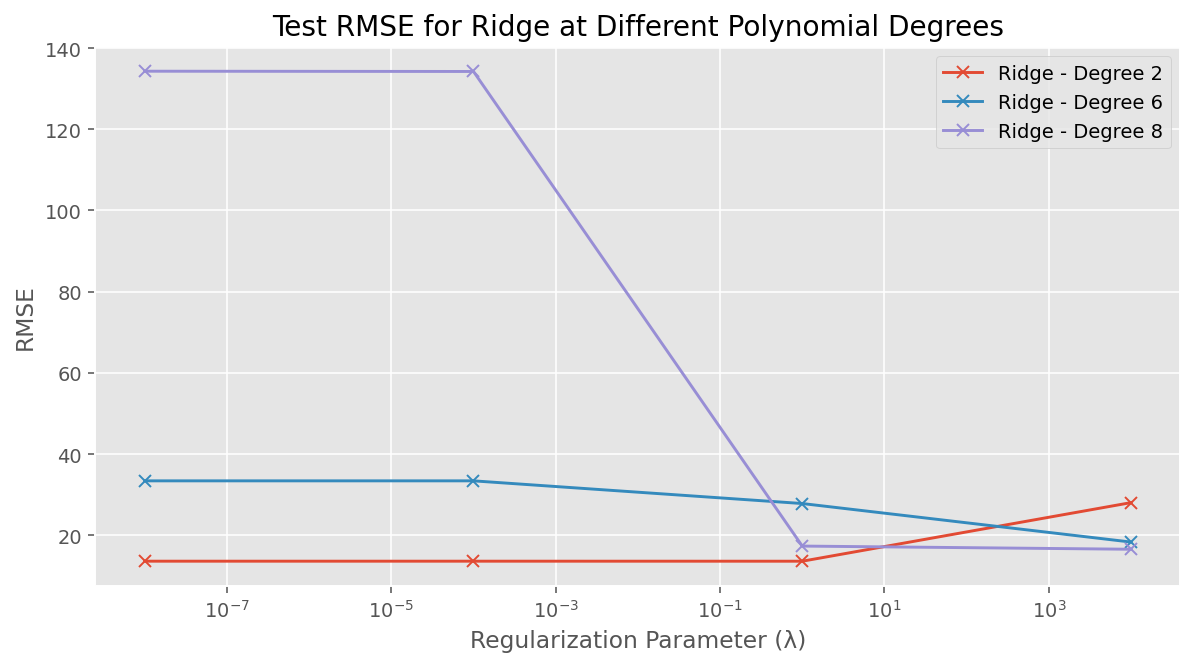

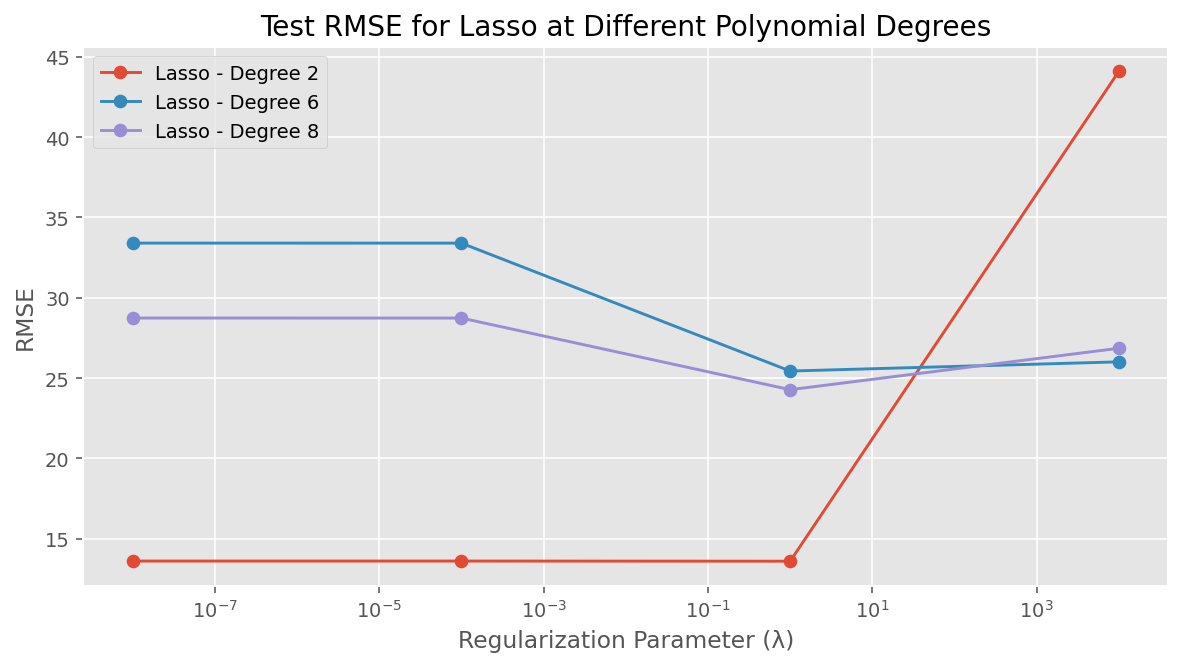

In [47]:
plt.figure(figsize=(10, 5))
for degree_idx, degree in enumerate(degrees):
    plt.plot(lambdas, ridge_rmse_test[degree_idx], marker='x', label=f'Ridge - Degree {degree}')
plt.xscale('log')
plt.xlabel('Regularization Parameter (λ)')
plt.ylabel('RMSE')
plt.title('Test RMSE for Ridge at Different Polynomial Degrees')
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
for degree_idx, degree in enumerate(degrees):
    plt.plot(lambdas, lasso_rmse_test[degree_idx], marker='o', label=f'Lasso - Degree {degree}')
plt.xscale('log')
plt.xlabel('Regularization Parameter (λ)')
plt.ylabel('RMSE')
plt.title('Test RMSE for Lasso at Different Polynomial Degrees')
plt.legend()
plt.show()


## 4. Classification with Regularization

Regularization is equally crucial in classification to prevent overly complex and jagged decision boundaries.

In Scikit-Learn's `LogisticRegression`, the cost function with $L_2$ regularization is parameterized by $C$:
$$J(\theta) = C \cdot \text{Cost}(X, y, \theta) + \frac{1}{2} \sum_{j=1}^{n} \theta_j^2$$

Note that $C = \frac{1}{\lambda}$ is the **inverse of regularization strength**:
- **Large $C$:** Weak regularization $\implies$ high model complexity, potential overfitting.
- **Small $C$:** Strong regularization $\implies$ simpler decision boundary, potential underfitting.


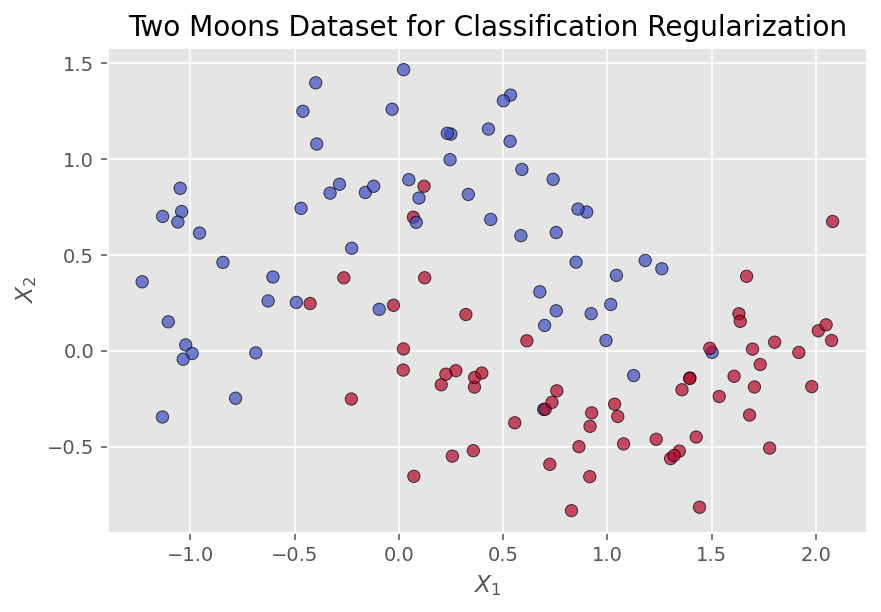

In [48]:
# Helper function for visualizing 2D decision boundary
def plot_2d_separator(classifier, X, fill=False, ax=None, eps=None):
    if ax is None:
        ax = plt.gca()
    if eps is None:
        eps = X.std() / 2.0
    x_min, x_max = X[:, 0].min() - eps, X[:, 0].max() + eps
    y_min, y_max = X[:, 1].min() - eps, X[:, 1].max() + eps
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = classifier.predict(grid)
    Z = Z.reshape(xx.shape)
    if fill:
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    else:
        ax.contour(xx, yy, Z, levels=[0.5], colors='k')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

# Create synthetic non-linear classification dataset
X_moons, y_moons = make_moons(n_samples=120, noise=0.25, random_state=0)

plt.figure(figsize=(7, 4.5))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, alpha=0.7, edgecolors='k', cmap=plt.cm.coolwarm, s=40)
plt.title('Two Moons Dataset for Classification Regularization')
plt.xlabel('$X_1$')
plt.ylabel('$X_2$')
plt.show()


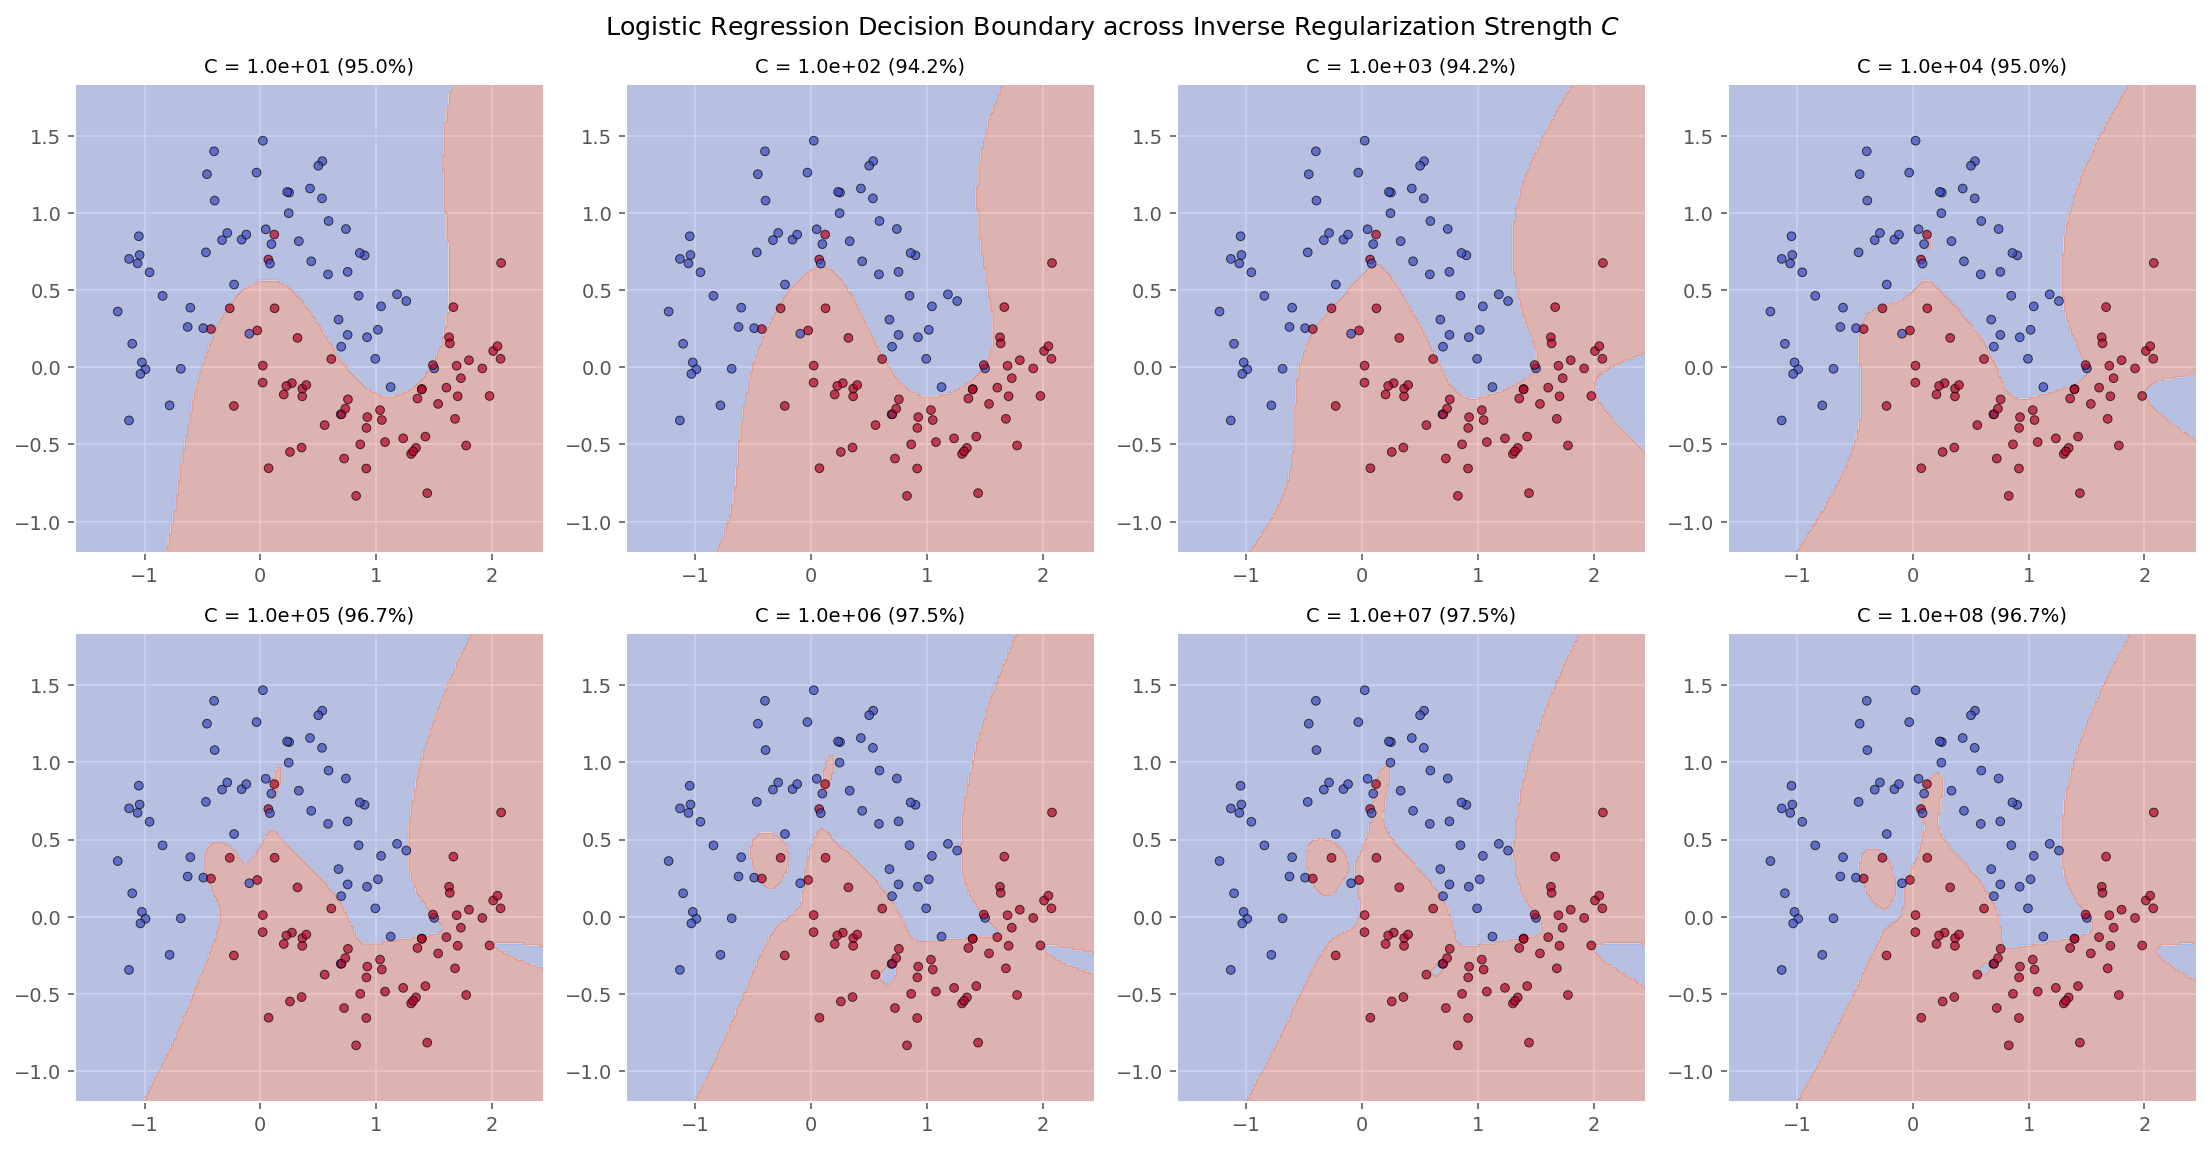

In [49]:
degree = 7
coeffs = [1e1, 1e2, 1e3, 1e4, 1e5, 1e6, 1e7, 1e8]

plt.figure(figsize=(16, 8))

for C in coeffs:
    plt.subplot(2, 4, coeffs.index(C) + 1)
    plt.tight_layout()
    poly_features = PolynomialFeatures(degree=degree, include_bias=False)
    log_reg = LogisticRegression(C=C, max_iter=2000)
    model = Pipeline([("poly_features", poly_features), ("logistic_regression", log_reg)])

    model.fit(X_moons, y_moons)
    accuracy = model.score(X_moons, y_moons)

    title = "C = {:.1e} ({:.1f}%)"
    plot_2d_separator(model, X_moons, fill=True)
    plt.scatter(X_moons[:, 0], X_moons[:, 1], s=20, c=y_moons, alpha=0.7, edgecolors='k', cmap=plt.cm.coolwarm)
    plt.title(title.format(C, accuracy * 100), fontsize=10)

plt.suptitle('Logistic Regression Decision Boundary across Inverse Regularization Strength $C$', fontsize=13, y=1.02)
plt.show()
